In [ ]:
# Cell 1 — Environment setup (Google Colab)
%pip -q install requests openpyxl joblib

In [ ]:
# Cell 2 — Imports and reproducibility
import os
import re
import json
import zipfile
import shutil
import warnings
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error,
    mean_squared_error, r2_score
)
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path('/content/toxiguard_data')
OUTPUT_DIR = Path('/content/toxiguard_outputs')
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PAGE = 'https://data.mendeley.com/datasets/vyz9zvddz4/2'
MENDELEY_DATASET_ID = 'vyz9zvddz4'
MENDELEY_VERSION = '2'
print('ToxiGuard environment ready.')
print('Dataset source:', DATASET_PAGE)

ToxiGuard environment ready.
Dataset source: https://data.mendeley.com/datasets/vyz9zvddz4/2


In [ ]:
# Cell 3 — Locate/download the dataset; fallback to Colab upload if needed
# This supports the original Hydrographic_Dataset1.csv schema. Public repositories
# sometimes change packaging, so the code checks actual column names rather than
# assuming that any downloaded CSV is the right dataset.

REQUIRED_COLUMNS = {'BIOTOXIN GROUP', 'VALUE', 'UTC DATE (YYYYMMDD)'}

def _norm_col(name):
    return re.sub(r'\s+', ' ', str(name).strip().upper().replace('_', ' '))

def _has_required_columns(path):
    path = Path(path)
    try:
        if path.suffix.lower() == '.csv':
            sample = pd.read_csv(path, nrows=3, low_memory=False)
            cols = {_norm_col(c) for c in sample.columns}
            return REQUIRED_COLUMNS.issubset(cols)
        if path.suffix.lower() in {'.xlsx', '.xls'}:
            book = pd.ExcelFile(path)
            for sheet in book.sheet_names:
                sample = pd.read_excel(path, sheet_name=sheet, nrows=3)
                cols = {_norm_col(c) for c in sample.columns}
                if REQUIRED_COLUMNS.issubset(cols):
                    return True
    except Exception:
        return False
    return False

def _expand_archives(root):
    for zpath in list(Path(root).rglob('*.zip')):
        try:
            target = Path(root) / (zpath.stem + '_extracted')
            target.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zpath, 'r') as zf:
                # Extract only files, avoiding parent traversal paths.
                for member in zf.infolist():
                    name = Path(member.filename)
                    if member.is_dir() or name.is_absolute() or '..' in name.parts:
                        continue
                    zf.extract(member, target)
        except Exception as exc:
            print(f'Could not extract {zpath.name}: {exc}')

def _download_mendeley_assets():
    """Best-effort downloader using Mendeley Data's public API.

    The source repository contains three Excel tables rather than guaranteeing a
    pre-merged modelling CSV. This downloads the archive and individual files;
    the later schema check only accepts a table that actually has the required
    target/date columns.
    """
    import requests
    session = requests.Session()
    session.headers.update({
        'User-Agent': 'ToxiGuard-student-project/1.0',
        'Accept': 'application/vnd.mendeley-public-dataset.1+json, application/json'
    })
    downloaded = 0

    # Preferred: whole-public-dataset ZIP redirect, documented by Mendeley Data.
    zip_urls = [
        f'https://api.data.mendeley.com/datasets/{MENDELEY_DATASET_ID}/zip/file_downloaded?version={MENDELEY_VERSION}',
        f'https://data.mendeley.com/datasets/{MENDELEY_DATASET_ID}/zip/file_downloaded?version={MENDELEY_VERSION}',
    ]
    for url in zip_urls:
        try:
            r = session.get(url, timeout=120, allow_redirects=True)
            if r.ok and len(r.content) > 1000 and r.content[:2] == b'PK':
                archive = DATA_DIR / 'mendeley_toxiguard_source.zip'
                archive.write_bytes(r.content)
                print('Downloaded public dataset archive:', archive.name, f'({len(r.content):,} bytes)')
                downloaded += 1
                break
        except Exception as exc:
            print('Whole-archive download attempt failed:', type(exc).__name__)

    # Query the public metadata endpoints for downloadable individual files.
    endpoints = [
        f'https://api.data.mendeley.com/datasets/{MENDELEY_DATASET_ID}?version={MENDELEY_VERSION}',
        f'https://api.data.mendeley.com/datasets/{MENDELEY_DATASET_ID}/files?version={MENDELEY_VERSION}&$limit=100',
        f'https://data.mendeley.com/public-api/datasets/{MENDELEY_DATASET_ID}/versions/{MENDELEY_VERSION}',
        f'https://data.mendeley.com/public-api/datasets/{MENDELEY_DATASET_ID}/versions/{MENDELEY_VERSION}/files',
    ]
    file_items = []
    for endpoint in endpoints:
        try:
            response = session.get(endpoint, timeout=30)
            if not response.ok:
                continue
            payload = response.json()
            if isinstance(payload, list):
                found = payload
            elif isinstance(payload, dict):
                found = payload.get('files') or payload.get('results') or payload.get('data') or payload.get('items') or []
                if isinstance(found, dict):
                    found = found.get('results') or found.get('files') or []
                if not found and isinstance(payload.get('dataset'), dict):
                    found = payload['dataset'].get('files', [])
            else:
                found = []
            if isinstance(found, list):
                file_items.extend(x for x in found if isinstance(x, dict))
        except Exception as exc:
            print('Metadata API attempt failed:', type(exc).__name__)

    unique = {}
    for item in file_items:
        key = str(item.get('id') or item.get('file_id') or item.get('filename') or item.get('name') or len(unique))
        unique[key] = item

    for item in unique.values():
        filename = str(item.get('filename') or item.get('name') or '').strip()
        file_id = item.get('id') or item.get('file_id')
        details = item.get('content_details') or {}
        if not filename:
            filename = f'dataset_file_{file_id or downloaded}'
        if not (filename.lower().endswith(('.csv', '.zip', '.xlsx', '.xls', '.7z')) or
                str(details.get('content_type', item.get('content_type', ''))).lower() in {'application/zip', 'text/csv', 'application/vnd.openxmlformats-officedocument.spreadsheetml.sheet'}):
            continue

        urls = []
        for value in (details.get('download_url'), item.get('download_url'), item.get('download_link'), item.get('url'), item.get('public_url')):
            if isinstance(value, str) and value.startswith('http'):
                urls.append(value)
            elif isinstance(value, dict) and isinstance(value.get('url'), str):
                urls.append(value['url'])
        if file_id:
            urls.extend([
                f'https://api.data.mendeley.com/datasets/{MENDELEY_DATASET_ID}/files/{file_id}/file_downloaded?version={MENDELEY_VERSION}',
                f'https://data.mendeley.com/datasets/{MENDELEY_DATASET_ID}/files/{file_id}/file_downloaded?version={MENDELEY_VERSION}',
                f'https://data.mendeley.com/public-files/datasets/{MENDELEY_DATASET_ID}/files/{file_id}/file_downloaded',
            ])
        safe_name = re.sub(r'[^A-Za-z0-9._-]+', '_', Path(filename).name) or f'file_{downloaded}'
        for url in dict.fromkeys(urls):
            try:
                r = session.get(url, timeout=90, allow_redirects=True)
                if not r.ok or len(r.content) < 100:
                    continue
                dest = DATA_DIR / safe_name
                if dest.suffix == '' and r.content[:2] == b'PK':
                    dest = dest.with_suffix('.zip')
                dest.write_bytes(r.content)
                downloaded += 1
                print('Downloaded source file:', dest.name, f'({len(r.content):,} bytes)')
                break
            except Exception:
                continue

    print('Mendeley download attempt complete; files downloaded:', downloaded)
    if downloaded == 0:
        print('The public API could not be reached from this runtime. Use the dataset page to download the source files manually.')

# Search files already in /content first (for example, a CSV exported from old Colab).
def _compatible_files(root='/content'):
    root = Path(root)
    hits = []
    for ext in ('*.csv', '*.xlsx', '*.xls'):
        for path in root.rglob(ext):
            if OUTPUT_DIR in path.parents or '.ipynb_checkpoints' in path.parts:
                continue
            if _has_required_columns(path):
                hits.append(path)
    # Prefer the known file name, then the shortest/most direct path.
    hits.sort(key=lambda p: (0 if 'hydrographic_dataset' in p.name.lower() else 1, len(str(p))))
    return hits

source_hits = _compatible_files('/content')
if not source_hits:
    print('No compatible local CSV found. Trying the public Mendeley Data API...')
    _download_mendeley_assets()
    _expand_archives(DATA_DIR)
    source_hits = _compatible_files(DATA_DIR)

if not source_hits:
    print('\nAutomatic download did not produce a unified table with the required columns.')
    print('Open this dataset page and download the data files: ', DATASET_PAGE)
    print('Upload a prepared/merged CSV from your previous project if available. The public source is distributed as three Excel tables; if automatic download only retrieves those raw tables, they need to be joined by sampling date/site before this model can use environmental predictors.')
    try:
        from google.colab import files
        uploaded = files.upload()
        source_hits = _compatible_files('/content')
    except Exception as exc:
        raise FileNotFoundError(
            'No compatible dataset was found. Upload a CSV/XLSX containing BIOTOXIN GROUP, VALUE, and UTC DATE (YYYYMMDD).'
        ) from exc

if not source_hits:
    raise ValueError(
        'Uploaded/downloaded files do not contain the expected unified table. '
        'Required columns: BIOTOXIN GROUP, VALUE, UTC DATE (YYYYMMDD). '
        'Check the source file. The public repository contains separate biotoxin, hydrographic, and phytoplankton tables; merge them by date/site into a unified table with BIOTOXIN GROUP, VALUE, and UTC DATE (YYYYMMDD), or upload the compatible CSV used by the previous project.'
    )

DATA_PATH = source_hits[0]
print('\nSelected dataset:', DATA_PATH)
print('Other compatible files found:', [p.name for p in source_hits[1:]])

if DATA_PATH.suffix.lower() == '.csv':
    df_raw = pd.read_csv(DATA_PATH, low_memory=False)
else:
    workbook = pd.ExcelFile(DATA_PATH)
    selected_sheet = None
    for sheet in workbook.sheet_names:
        preview = pd.read_excel(DATA_PATH, sheet_name=sheet, nrows=3)
        if REQUIRED_COLUMNS.issubset({_norm_col(c) for c in preview.columns}):
            selected_sheet = sheet
            break
    if selected_sheet is None:
        raise ValueError('No worksheet contains the required columns.')
    df_raw = pd.read_excel(DATA_PATH, sheet_name=selected_sheet)

df_raw.columns = [str(c).strip() for c in df_raw.columns]
print('Raw shape:', df_raw.shape)
print('Column names:', df_raw.columns.tolist())
display(df_raw.head())


Selected dataset: /content/Biotoxins in bivalves (1).xlsx
Other compatible files found: []
Raw shape: (5446, 15)
Column names: ['STATION', 'LATITUDE (degrees North)', 'LONGITUDE (degrees East)', 'DATUM', 'UTC DATE (YYYYMMDD)', 'TYPE OF MOLLUSC', 'SPECIES', 'LABORATORY', 'BIOTOXIN GROUP', 'VARIABLE (long)', 'VARIABLE (abbreviation)', '<=>', 'VALUE', 'UNITS (abbreviation)', 'UNITS (long)']


,STATION,LATITUDE (degrees North),LONGITUDE (degrees East),DATUM,UTC DATE (YYYYMMDD),TYPE OF MOLLUSC,SPECIES,LABORATORY,BIOTOXIN GROUP,VARIABLE (long),VARIABLE (abbreviation),<=>,VALUE,UNITS (abbreviation),UNITS (long)
0,AZTI pilot plant,43.355712,-2.448422,WGS84,20131203,Mussel,Mytilus galloprovincialis,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight)
1,AZTI pilot plant,43.355712,-2.448422,WGS84,20140527,Mussel,Mytilus galloprovincialis,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight)
2,AZTI pilot plant,43.355712,-2.448422,WGS84,20140527,Pacific oyster,Magallana gigas,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight)
3,AZTI pilot plant,43.355712,-2.448422,WGS84,20140623,Mussel,Mytilus galloprovincialis,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight)
4,AZTI pilot plant,43.355712,-2.448422,WGS84,20140805,Mussel,Mytilus galloprovincialis,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight)


In [ ]:
# Cell 4 — Clean the data and preserve censoring information

def find_column(df, candidates):
    lookup = {_norm_col(c): c for c in df.columns}
    for candidate in candidates:
        if _norm_col(candidate) in lookup:
            return lookup[_norm_col(candidate)]
    return None

bio_col = find_column(df_raw, ['BIOTOXIN GROUP'])
value_col = find_column(df_raw, ['VALUE'])
date_col = find_column(df_raw, ['UTC DATE (YYYYMMDD)', 'SAMPLE DATE', 'DATE'])
comp_col = find_column(df_raw, ['<=>', 'MEASUREMENT_STATUS', 'MEASUREMENT STATUS', 'COMPARATOR'])
if bio_col is None or value_col is None or date_col is None:
    raise ValueError(f'Required columns were not found. Available columns: {df_raw.columns.tolist()}')

df = df_raw.copy()
df.columns = [str(c).strip() for c in df.columns]
# The source often stores the censoring sign separately in <=>. Also parse signs
# embedded in VALUE in case a future source version combines them.
raw_value_text = df[value_col].astype(str).str.strip()
embedded_comparator = raw_value_text.str.extract(r'^\s*([<>]=?)', expand=False)
if comp_col:
    comparator = df[comp_col].astype('string').str.strip()
    comparator = comparator.where(comparator.isin(['<', '<=', '=', '>', '>=']), embedded_comparator)
else:
    comparator = embedded_comparator
comparator = comparator.fillna('=')
comparator = comparator.replace({'<=': '<', '>=': '>', '==': '='})
value_text_clean = raw_value_text.str.replace(r'^\s*[<>]=?\s*', '', regex=True)
df['VALUE'] = pd.to_numeric(value_text_clean, errors='coerce')
df['MEASUREMENT_STATUS'] = comparator.astype(str)

# Parse dates safely across YYYYMMDD and ordinary date formats.
date_text = df[date_col].astype(str).str.strip()
parsed_yyyymmdd = pd.to_datetime(date_text, format='%Y%m%d', errors='coerce')
parsed_general = pd.to_datetime(date_text, errors='coerce', utc=False)
df['SAMPLE_DATE'] = parsed_yyyymmdd.fillna(parsed_general)

# Standardize toxin group names.
def normalise_toxin_group(value, variable=''):
    text = str(value).strip().lower()
    var = str(variable).strip().upper()
    combined = f'{text} {var}'.lower()
    if 'amnesic' in combined or var == 'DA' or 'domoic' in combined or text == 'asp':
        return 'ASP'
    if 'paralytic' in combined or var in {'PSP', 'STX'} or 'saxitoxin' in combined or text == 'psp':
        return 'PSP'
    if 'azaspiracid' in combined or 'aza group' in combined or var.startswith('AZA') or text == 'aza':
        return 'AZA'
    if 'pectenotoxin' in combined or 'ptx group' in combined or var.startswith('PTX') or text == 'ptx':
        return 'PTX'
    if 'yessotoxin' in combined or 'ytx group' in combined or var.startswith('YTX') or text == 'ytx':
        return 'YTX'
    if 'lipophilic (ao' in combined or 'okadaic' in combined or 'dtx' in var.lower() or var == 'OA' or text == 'ao':
        return 'AO'
    return 'OTHER'

variable_col = find_column(df, ['VARIABLE (abbreviation)', 'VARIABLE ABBREVIATION'])
variable_values = df[variable_col] if variable_col else pd.Series('', index=df.index)
df['TOXIN_GROUP'] = [normalise_toxin_group(a, b) for a, b in zip(df[bio_col], variable_values)]

# Normalize known hydrographic numeric fields; unusual sentinel values become missing.
NUMERIC_CANDIDATES = [
    'LATITUDE (degrees North)', 'LONGITUDE (degrees East)', 'PRESSURE (dbar)',
    'TEMPERATURE (°C)', 'SALINITY', 'SIGMA THETA (kg m-3)', 'LT (%)',
    'PAR (µmol m-2 s-1)', 'CHLOROPHYLL-a (µg l-1)',
    'DISSOLVED OXYGEN (ml l-1)', 'OXYGEN SATURATION (%)', 'SAMPLING DEPTH (m)'
]
for candidate in NUMERIC_CANDIDATES:
    col = find_column(df, [candidate])
    if col:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df.loc[df[col].isin([-999, -9999]), col] = np.nan

# Add calendar features known at prediction time.
df['YEAR'] = df['SAMPLE_DATE'].dt.year
df['MONTH'] = df['SAMPLE_DATE'].dt.month
df['DAY_OF_YEAR'] = df['SAMPLE_DATE'].dt.dayofyear
df['SEASON'] = df['MONTH'].map({
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
})

before_rows = len(df)
df = df.dropna(subset=['VALUE', 'SAMPLE_DATE', 'TOXIN_GROUP']).copy()
df = df[df['VALUE'] >= 0].copy()
df = df[df['TOXIN_GROUP'] != 'OTHER'].copy()
df = df.sort_values(['SAMPLE_DATE', 'STATION'] if 'STATION' in df.columns else ['SAMPLE_DATE']).reset_index(drop=True)

print(f'Rows retained: {len(df):,} / {before_rows:,}')
print('Date range:', df['SAMPLE_DATE'].min().date(), 'to', df['SAMPLE_DATE'].max().date())
print('\nRows by toxin group:')
display(df['TOXIN_GROUP'].value_counts().rename_axis('TOXIN_GROUP').to_frame('Rows'))
print('\nMeasurement status by toxin group:')
display(pd.crosstab(df['TOXIN_GROUP'], df['MEASUREMENT_STATUS'], margins=True))
print('\nMissingness in likely environmental variables:')
missing_report = df.isna().mean().sort_values(ascending=False).rename('missing_fraction').to_frame()
display(missing_report.head(15))

Rows retained: 5,446 / 5,446
Date range: 2013-12-03 to 2023-06-22

Rows by toxin group:


,Rows
TOXIN_GROUP,
PSP,1694
YTX,1152
AZA,918
AO,840
PTX,560
ASP,282



Measurement status by toxin group:


MEASUREMENT_STATUS,<,=,All
TOXIN_GROUP,,,
AO,745,95,840
ASP,272,10,282
AZA,918,0,918
PSP,1666,28,1694
PTX,560,0,560
YTX,938,214,1152
All,5099,347,5446



Missingness in likely environmental variables:


,missing_fraction
STATION,0.0
LATITUDE (degrees North),0.0
LONGITUDE (degrees East),0.0
DATUM,0.0
UTC DATE (YYYYMMDD),0.0
TYPE OF MOLLUSC,0.0
SPECIES,0.0
LABORATORY,0.0
BIOTOXIN GROUP,0.0
VARIABLE (long),0.0


# Scientific Multi-Dataset Integration & Temporal Alignment

In this section, we load and integrate all three uploaded files:
1. **Biotoxins in bivalves.xlsx**
2. **Hydrographic_variables.xlsx**
3. **Toxic_phytoplankton_v2.xlsx**

We align them temporally and spatially (by Station) using a safe non-leakage join strategy.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

# Target file paths (preferring manually uploaded (1).xlsx copies if present)
biotoxin_path = Path('/content/Biotoxins in bivalves (1).xlsx') if Path('/content/Biotoxins in bivalves (1).xlsx').exists() else Path('/content/Biotoxins in bivalves.xlsx')
hydro_path = Path('/content/Hydrographic_variables (1).xlsx') if Path('/content/Hydrographic_variables (1).xlsx').exists() else Path('/content/Hydrographic_variables.xlsx')
phyto_path = Path('/content/Toxic_phytoplankton_v2 (1).xlsx') if Path('/content/Toxic_phytoplankton_v2 (1).xlsx').exists() else Path('/content/Toxic_phytoplankton_v2.xlsx')

# Final validation check on the Excel files
for p in [biotoxin_path, hydro_path, phyto_path]:
    if not p.exists():
        raise FileNotFoundError(f"Could not find '{p.name}' in /content/. Please drag and drop the manually downloaded file into the Google Colab file browser.")
    if p.stat().st_size < 10000:
        raise ValueError(f"File '{p.name}' is too small ({p.stat().st_size} bytes) and appears to be a corrupt redirect webpage. Please delete it, download the original file from Mendeley, and re-upload.")

# Helper function to load the correct spreadsheet from the workbook
def load_data_sheet(path, sheet_name_contains):
    xls = pd.ExcelFile(path)
    target_sheet = None
    for sheet in xls.sheet_names:
        if sheet_name_contains.lower() in sheet.lower():
            target_sheet = sheet
            break
    if target_sheet is None:
        # Fallback to the second sheet (index 1) if the specific name is not found
        target_sheet = xls.sheet_names[1] if len(xls.sheet_names) > 1 else xls.sheet_names[0]
    print(f"Loading sheet '{target_sheet}' from '{path.name}'...")
    return pd.read_excel(path, sheet_name=target_sheet, engine='openpyxl')

# 1. Load Biotoxins
df_bio = load_data_sheet(biotoxin_path, 'Biotoxins')
df_bio.columns = [str(c).strip() for c in df_bio.columns]
df_bio['SAMPLE_DATE'] = pd.to_datetime(df_bio['UTC DATE (YYYYMMDD)'].astype(str).str.strip(), format='%Y%m%d', errors='coerce')

# 2. Load Hydrographic Variables
df_hydro = load_data_sheet(hydro_path, 'Hydro')
df_hydro.columns = [str(c).strip() for c in df_hydro.columns]
df_hydro['HYDRO_DATE'] = pd.to_datetime(df_hydro['UTC DATE (YYYYMMDD)'].astype(str).str.strip(), format='%Y%m%d', errors='coerce')

# 3. Load Phytoplankton
df_phyto = load_data_sheet(phyto_path, 'Phyto')
df_phyto.columns = [str(c).strip() for c in df_phyto.columns]
df_phyto['PHYTO_DATE'] = pd.to_datetime(df_phyto['UTC DATE (YYYYMMDD)'].astype(str).str.strip(), format='%Y%m%d', errors='coerce')

print(f"Raw records successfully loaded - Biotoxins: {len(df_bio)}, Hydrographic: {len(df_hydro)}, Phytoplankton: {len(df_phyto)}")

# Aggregate variables to Station-Date level to avoid combinations explosion
hydro_cols_to_mean = [c for c in df_hydro.columns if any(k in c.upper() for k in ['TEMP', 'SALINITY', 'PRESSURE', 'OXYGEN', 'CHLOROPHYLL', 'SIGMA'])]
hydro_agg = df_hydro.groupby(['STATION', 'HYDRO_DATE'])[hydro_cols_to_mean].mean().reset_index()

# Dynamically find the correct abundance/value column in phytoplankton dataset
phyto_val_col = None
for col in df_phyto.columns:
    if any(k in col.upper() for k in ['ABUNDANCE', 'VALUE', 'CELLS', 'COUNT']):
        phyto_val_col = col
        break
if phyto_val_col is None:
    # Fallback to the last column if no matching keyword is found
    phyto_val_col = df_phyto.columns[-1]
print(f"Using column '{phyto_val_col}' as phytoplankton abundance value.")

phyto_agg = df_phyto.groupby(['STATION', 'PHYTO_DATE'])[[phyto_val_col]].sum().rename(columns={phyto_val_col: 'PHYTO_TOTAL_ABUNDANCE'}).reset_index()

# 4. Temporal & Spatial Integration (Non-leakage match)
print("Integrating datasets using safe temporal and spatial alignment...")
merged_rows = []
for idx, row in df_bio.iterrows():
    station = row['STATION']
    bio_date = row['SAMPLE_DATE']
    if pd.isna(bio_date):
        continue

    # Hydro matching (up to 7 days prior)
    station_hydro = hydro_agg[hydro_agg['STATION'] == station]
    valid_hydro = station_hydro[(station_hydro['HYDRO_DATE'] <= bio_date) & (station_hydro['HYDRO_DATE'] >= bio_date - pd.Timedelta(days=7))]
    best_hydro = valid_hydro.sort_values(by='HYDRO_DATE', ascending=False).head(1)

    # Phyto matching (up to 7 days prior)
    station_phyto = phyto_agg[phyto_agg['STATION'] == station]
    valid_phyto = station_phyto[(station_phyto['PHYTO_DATE'] <= bio_date) & (station_phyto['PHYTO_DATE'] >= bio_date - pd.Timedelta(days=7))]
    best_phyto = valid_phyto.sort_values(by='PHYTO_DATE', ascending=False).head(1)

    combined_row = row.to_dict()
    if not best_hydro.empty:
        for col in hydro_cols_to_mean:
            combined_row[col] = best_hydro.iloc[0][col]
    if not best_phyto.empty:
        combined_row['PHYTO_TOTAL_ABUNDANCE'] = best_phyto.iloc[0]['PHYTO_TOTAL_ABUNDANCE']
    merged_rows.append(combined_row)

df_integrated = pd.DataFrame(merged_rows)
print(f"Integrated dataset successfully constructed. Shape: {df_integrated.shape}")

df_raw = df_integrated
display(df_raw.head())

Loading sheet 'Biotoxins' from 'Biotoxins in bivalves (1).xlsx'...
Loading sheet 'Hydrographic variables' from 'Hydrographic_variables (1).xlsx'...
Loading sheet 'Phytoplankton' from 'Toxic_phytoplankton_v2 (1).xlsx'...
Raw records successfully loaded - Biotoxins: 5446, Hydrographic: 8195, Phytoplankton: 532
Using column 'Pseudo-nitzschia americana/brasiliana (cells l-1)' as phytoplankton abundance value.
Integrating datasets using safe temporal and spatial alignment...
Integrated dataset successfully constructed. Shape: (5446, 16)


,STATION,LATITUDE (degrees North),LONGITUDE (degrees East),DATUM,UTC DATE (YYYYMMDD),TYPE OF MOLLUSC,SPECIES,LABORATORY,BIOTOXIN GROUP,VARIABLE (long),VARIABLE (abbreviation),<=>,VALUE,UNITS (abbreviation),UNITS (long),SAMPLE_DATE
0,AZTI pilot plant,43.355712,-2.448422,WGS84,20131203,Mussel,Mytilus galloprovincialis,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight),2013-12-03
1,AZTI pilot plant,43.355712,-2.448422,WGS84,20140527,Mussel,Mytilus galloprovincialis,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight),2014-05-27
2,AZTI pilot plant,43.355712,-2.448422,WGS84,20140527,Pacific oyster,Magallana gigas,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight),2014-05-27
3,AZTI pilot plant,43.355712,-2.448422,WGS84,20140623,Mussel,Mytilus galloprovincialis,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight),2014-06-23
4,AZTI pilot plant,43.355712,-2.448422,WGS84,20140805,Mussel,Mytilus galloprovincialis,INTECMAR,Amnesic Shellfish Poisoning (ASP),Domoic acid,DA,<,2.0,mg DA/kg,mg domoic acid/kg shellfish flesh (wet weight),2014-08-05


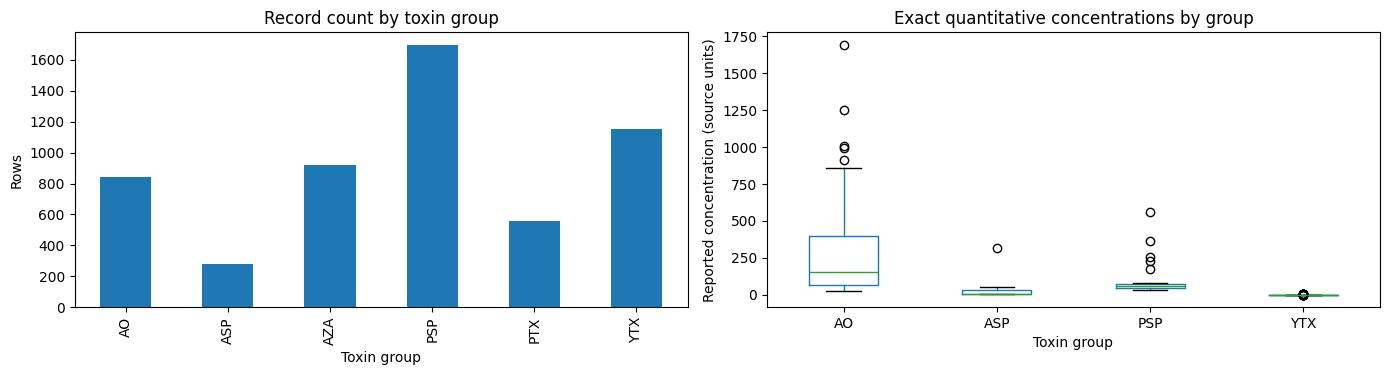

Exact quantified records by toxin group:


,count,median,mean,min,max
TOXIN_GROUP,,,,,
AO,95,153.000,269.6653,25.00,1693.0
ASP,10,6.150,46.1200,1.60,318.0
PSP,28,61.500,101.6071,29.00,560.0
YTX,214,0.274,0.4666,0.06,3.6


Censoring share: 93.63 %
Note: different toxin groups may use different units. Do not pool concentrations into one regression target.


In [ ]:
# Cell 5 — Exploratory data analysis
exact_df = df[df['MEASUREMENT_STATUS'].eq('=')].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['TOXIN_GROUP'].value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set_title('Record count by toxin group')
axes[0].set_xlabel('Toxin group')
axes[0].set_ylabel('Rows')

if len(exact_df):
    exact_df.boxplot(column='VALUE', by='TOXIN_GROUP', ax=axes[1], grid=False, rot=0)
    axes[1].set_title('Exact quantitative concentrations by group')
    axes[1].set_xlabel('Toxin group')
    axes[1].set_ylabel('Reported concentration (source units)')
    fig.suptitle('')
else:
    axes[1].text(0.5, 0.5, 'No exact measurements found', ha='center', va='center')
    axes[1].set_axis_off()
plt.tight_layout()
plt.show()

print('Exact quantified records by toxin group:')
exact_summary = exact_df.groupby('TOXIN_GROUP')['VALUE'].agg(['count', 'median', 'mean', 'min', 'max']).round(4)
display(exact_summary)

print('Censoring share:', round(df['MEASUREMENT_STATUS'].isin(['<', '>']).mean() * 100, 2), '%')
print('Note: different toxin groups may use different units. Do not pool concentrations into one regression target.')

In [ ]:
# Cell 6 — Chronological split and training-only risk labels
# 70% earliest dates = training, next 15% = validation, latest 15% = final test.
# Split cutoffs are based on unique dates so observations collected on the same
# date cannot be split between the three sets.

RISK_QUANTILE = 0.80       # top 20% relative high concentration within each toxin group
MIN_EXACT_TRAIN_PER_GROUP = 10

unique_dates = np.array(sorted(df['SAMPLE_DATE'].dropna().unique()))
if len(unique_dates) < 10:
    raise ValueError('Too few distinct dates for chronological train/validation/test evaluation.')
cut_train = unique_dates[max(0, int(len(unique_dates) * 0.70) - 1)]
cut_val = unique_dates[max(0, int(len(unique_dates) * 0.85) - 1)]
df['SPLIT'] = np.where(
    df['SAMPLE_DATE'] <= cut_train, 'train',
    np.where(df['SAMPLE_DATE'] <= cut_val, 'validation', 'test')
)

print('Train through:', pd.Timestamp(cut_train).date())
print('Validation through:', pd.Timestamp(cut_val).date())
print('Split counts:')
display(df['SPLIT'].value_counts().reindex(['train', 'validation', 'test']).rename('rows').to_frame())

train_exact = df[(df['SPLIT'] == 'train') & (df['MEASUREMENT_STATUS'] == '=')].copy()
exact_counts = train_exact.groupby('TOXIN_GROUP')['VALUE'].count()
eligible_groups = exact_counts[exact_counts >= MIN_EXACT_TRAIN_PER_GROUP].index.tolist()
thresholds = train_exact[train_exact['TOXIN_GROUP'].isin(eligible_groups)].groupby('TOXIN_GROUP')['VALUE'].quantile(RISK_QUANTILE)

if thresholds.empty:
    raise ValueError('No toxin group has enough exact training measurements to form a stable training-only risk threshold.')

threshold_table = pd.DataFrame({
    'train_exact_count': exact_counts,
    'relative_risk_threshold': thresholds
}).sort_index()
threshold_table['threshold_quantile'] = RISK_QUANTILE
print('Risk thresholds learned only from exact TRAIN-period records:')
display(threshold_table)

# Create labels only when justified by the reported measurement.
# Exact (=): compare true value to the threshold.
# Left-censored (<): when its upper bound <= threshold, it is known to be low.
# Right-censored (>): when its lower bound >= threshold, it is known to be high.
df['RISK_LABEL'] = pd.NA
for toxin_group, threshold in thresholds.items():
    group_mask = df['TOXIN_GROUP'].eq(toxin_group)
    exact_mask = group_mask & df['MEASUREMENT_STATUS'].eq('=')
    df.loc[exact_mask & (df['VALUE'] >= threshold), 'RISK_LABEL'] = 'High Risk'
    df.loc[exact_mask & (df['VALUE'] < threshold), 'RISK_LABEL'] = 'Low Risk'

    left_mask = group_mask & df['MEASUREMENT_STATUS'].eq('<')
    df.loc[left_mask & (df['VALUE'] <= threshold), 'RISK_LABEL'] = 'Low Risk'
    right_mask = group_mask & df['MEASUREMENT_STATUS'].eq('>')
    df.loc[right_mask & (df['VALUE'] >= threshold), 'RISK_LABEL'] = 'High Risk'

labelled = df[df['RISK_LABEL'].notna()].copy()
labelled['TARGET_HIGH_RISK'] = (labelled['RISK_LABEL'] == 'High Risk').astype(int)
print('\nKnown relative-risk label counts:')
display(pd.crosstab(labelled['SPLIT'], labelled['RISK_LABEL'], margins=True))
print('Rows excluded from classification because status/threshold did not establish a reliable label:', int(df['RISK_LABEL'].isna().sum()))
print('\nThese are data-derived relative labels, not toxin-specific statutory safety limits.')

Train through: 2021-09-06
Validation through: 2022-05-03
Split counts:


,rows
SPLIT,
train,2876
validation,997
test,1573


Risk thresholds learned only from exact TRAIN-period records:


,train_exact_count,relative_risk_threshold,threshold_quantile
TOXIN_GROUP,,,
AO,79,455.4000,0.8
ASP,6,NaN,0.8
PSP,3,NaN,0.8
YTX,97,0.7708,0.8



Known relative-risk label counts:


RISK_LABEL,High Risk,Low Risk,All
SPLIT,,,
test,1,503,504
train,36,1144,1180
validation,17,291,308
All,54,1938,1992


Rows excluded from classification because status/threshold did not establish a reliable label: 3454

These are data-derived relative labels, not toxin-specific statutory safety limits.


In [ ]:
# Cell 7 — Feature pipeline and model comparison for Stage 1 classification
# No current VALUE, measurement comparator/status, threshold, or risk label enters X.

CAT_CANDIDATES = [
    'TOXIN_GROUP', 'VARIABLE (abbreviation)', 'TYPE OF MOLLUSC',
    'SPECIES', 'STATION', 'SAMPLING METHOD', 'SEASON'
]
NUM_CANDIDATES = [
    'LATITUDE (degrees North)', 'LONGITUDE (degrees East)', 'PRESSURE (dbar)',
    'TEMPERATURE (°C)', 'SALINITY', 'SIGMA THETA (kg m-3)', 'LT (%)',
    'PAR (µmol m-2 s-1)', 'CHLOROPHYLL-a (µg l-1)',
    'DISSOLVED OXYGEN (ml l-1)', 'OXYGEN SATURATION (%)', 'SAMPLING DEPTH (m)',
    'YEAR', 'MONTH', 'DAY_OF_YEAR'
]
cat_features = [c for c in CAT_CANDIDATES if c in labelled.columns]
num_features = [c for c in NUM_CANDIDATES if c in labelled.columns]
FEATURES = cat_features + num_features
if not FEATURES:
    raise ValueError('No valid environmental/metadata predictors were found. Verify the dataset column names.')

# Cast numeric predictors to numeric again in case source CSV columns were strings.
for c in num_features:
    labelled[c] = pd.to_numeric(labelled[c], errors='coerce')
    df[c] = pd.to_numeric(df[c], errors='coerce')

print('Predictors used:', FEATURES)
print('Features excluded to prevent target leakage: VALUE, MEASUREMENT_STATUS, <=>, RISK_LABEL, and threshold columns.')

# Compatibility with older/newer scikit-learn versions.
try:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:
    onehot = OneHotEncoder(handle_unknown='ignore', sparse=True)

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler(with_mean=False))
])
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', onehot)
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_features),
    ('cat', categorical_pipe, cat_features)
], remainder='drop')

classifier_candidates = {
    'RandomForest': RandomForestClassifier(
        n_estimators=400,
        max_depth=8,
        min_samples_leaf=4,
        max_features='sqrt',
        class_weight='balanced_subsample',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

train_cls = labelled[labelled['SPLIT'] == 'train'].copy()
val_cls = labelled[labelled['SPLIT'] == 'validation'].copy()
test_cls = labelled[labelled['SPLIT'] == 'test'].copy()
if train_cls['TARGET_HIGH_RISK'].nunique() < 2:
    raise ValueError('Training split has only one class. Increase available data or change the chronological split.')
if val_cls.empty or test_cls.empty:
    raise ValueError('Validation or test split has no labelled samples. Check date coverage and source data.')

X_train, y_train = train_cls[FEATURES], train_cls['TARGET_HIGH_RISK']
X_val, y_val = val_cls[FEATURES], val_cls['TARGET_HIGH_RISK']
X_test, y_test = test_cls[FEATURES], test_cls['TARGET_HIGH_RISK']

# Fit every candidate on training only; use validation average precision to select.
comparison_rows = []
trained_classifiers = {}
for name, estimator in classifier_candidates.items():
    pipe = Pipeline([('preprocess', clone(preprocessor)), ('model', clone(estimator))])
    pipe.fit(X_train, y_train)
    trained_classifiers[name] = pipe
    val_prob = pipe.predict_proba(X_val)[:, list(pipe.classes_).index(1)]
    val_pred_05 = (val_prob >= 0.5).astype(int)
    ap = average_precision_score(y_val, val_prob) if y_val.nunique() == 2 else np.nan
    comparison_rows.append({
        'model': name,
        'validation_accuracy_at_0.50': accuracy_score(y_val, val_pred_05),
        'validation_precision_at_0.50': precision_score(y_val, val_pred_05, zero_division=0),
        'validation_recall_at_0.50': recall_score(y_val, val_pred_05, zero_division=0),
        'validation_f1_at_0.50': f1_score(y_val, val_pred_05, zero_division=0),
        'validation_PR_AUC': ap
    })

classifier_comparison = pd.DataFrame(comparison_rows).sort_values(
    ['validation_PR_AUC', 'validation_f1_at_0.50'], ascending=False, na_position='last'
).reset_index(drop=True)
print('Validation-only classifier comparison (test has not been used):')
display(classifier_comparison)

best_classifier_name = classifier_comparison.iloc[0]['model']
best_classifier = trained_classifiers[best_classifier_name]
val_prob = best_classifier.predict_proba(X_val)[:, list(best_classifier.classes_).index(1)]

# Choose a decision threshold from validation F1 only. Fall back to 0.50 if
# validation does not contain both classes or too few positive validation cases.
if y_val.nunique() == 2 and int(y_val.sum()) >= 3:
    grid = np.linspace(0.10, 0.90, 81)
    threshold_scores = []
    for threshold in grid:
        pred = (val_prob >= threshold).astype(int)
        threshold_scores.append((f1_score(y_val, pred, zero_division=0), precision_score(y_val, pred, zero_division=0), threshold))
    # Maximise F1; if tied, prefer the threshold with higher precision.
    best_f1, best_precision, CLASSIFICATION_THRESHOLD = max(threshold_scores, key=lambda x: (x[0], x[1]))
else:
    CLASSIFICATION_THRESHOLD = 0.50

print(f'Chosen model: {best_classifier_name}')
print(f'Decision threshold selected using VALIDATION only: {CLASSIFICATION_THRESHOLD:.3f}')

# Metric helper with positive class = High Risk.
def classification_metrics(y_true, probabilities, threshold):
    y_true = np.asarray(y_true).astype(int)
    y_pred = (np.asarray(probabilities) >= threshold).astype(int)
    result = {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision_high_risk': precision_score(y_true, y_pred, zero_division=0),
        'recall_high_risk': recall_score(y_true, y_pred, zero_division=0),
        'f1_high_risk': f1_score(y_true, y_pred, zero_division=0),
        'n_samples': len(y_true),
        'n_high_risk_actual': int(y_true.sum()),
        'n_high_risk_predicted': int(y_pred.sum())
    }
    result['roc_auc'] = roc_auc_score(y_true, probabilities) if len(np.unique(y_true)) == 2 else np.nan
    result['average_precision_PR_AUC'] = average_precision_score(y_true, probabilities) if len(np.unique(y_true)) == 2 else np.nan
    return result, y_pred

train_prob = best_classifier.predict_proba(X_train)[:, list(best_classifier.classes_).index(1)]
test_prob = best_classifier.predict_proba(X_test)[:, list(best_classifier.classes_).index(1)]
train_metrics, train_pred = classification_metrics(y_train, train_prob, CLASSIFICATION_THRESHOLD)
val_metrics, val_pred = classification_metrics(y_val, val_prob, CLASSIFICATION_THRESHOLD)
test_metrics, test_pred = classification_metrics(y_test, test_prob, CLASSIFICATION_THRESHOLD)

classification_metrics_table = pd.DataFrame([
    {'split': 'train', **train_metrics},
    {'split': 'validation', **val_metrics},
    {'split': 'test (final holdout)', **test_metrics}
])
print('\nFinal classification metrics:')
display(classification_metrics_table.round(4))
print('\nFinal held-out TEST report:')
print(classification_report(y_test, test_pred, labels=[0, 1], target_names=['Low Risk', 'High Risk'], zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=[0, 1], display_labels=['Low Risk', 'High Risk'],
    cmap='Blues', ax=ax, colorbar=False
)
ax.set_title('ToxiGuard — final chronological test set')
plt.tight_layout()
plt.show()

print('Overfitting diagnostic: compare train vs validation/test F1 and accuracy above.')
print('High train but weak validation/test suggests overfitting or weak generalisation; low values on all splits suggest the features do not explain the risk label well.')

Predictors used: ['TOXIN_GROUP', 'VARIABLE (abbreviation)', 'TYPE OF MOLLUSC', 'SPECIES', 'STATION', 'SEASON', 'LATITUDE (degrees North)', 'LONGITUDE (degrees East)', 'YEAR', 'MONTH', 'DAY_OF_YEAR']
Features excluded to prevent target leakage: VALUE, MEASUREMENT_STATUS, <=>, RISK_LABEL, and threshold columns.


Top predictors (tree impurity importance):


,feature,importance
4,num__DAY_OF_YEAR,0.223950
3,num__MONTH,0.145863
12,cat__VARIABLE (abbreviation)_OA,0.105514
2,num__YEAR,0.092917
22,cat__SEASON_Summer,0.043552
13,cat__VARIABLE (abbreviation)_YTX,0.043255
11,cat__VARIABLE (abbreviation)_HomoYTX,0.040174
8,cat__VARIABLE (abbreviation)_45OHHomoYTX,0.038279
9,cat__VARIABLE (abbreviation)_DTX1,0.036273
10,cat__VARIABLE (abbreviation)_DTX2,0.034359


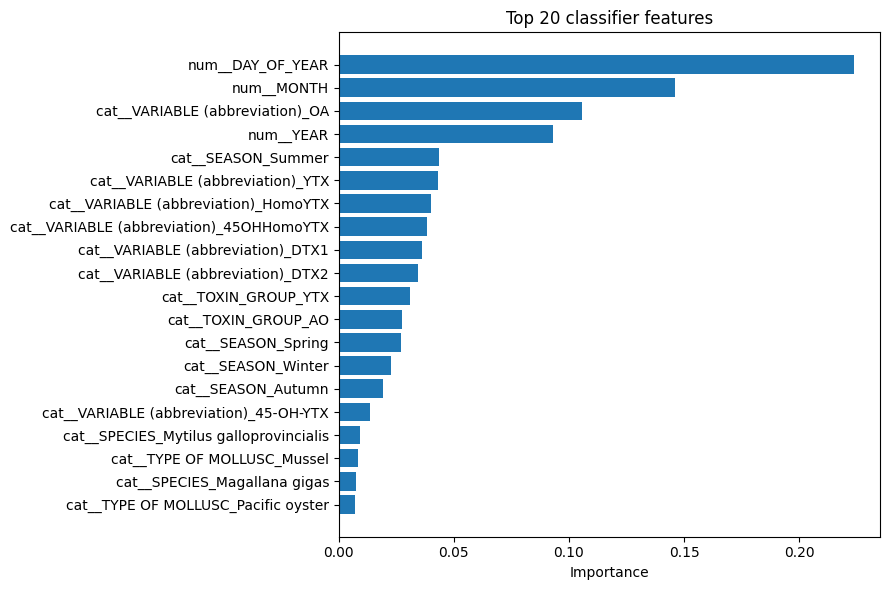

In [ ]:
# Cell 8 — Feature importance for Stage 1
# Tree impurity importance is shown for tree models. For Logistic Regression,
# absolute coefficients are used. Importance indicates model reliance, not causation.
try:
    fitted_preprocessor = best_classifier.named_steps['preprocess']
    fitted_estimator = best_classifier.named_steps['model']
    expanded_names = fitted_preprocessor.get_feature_names_out()
    if hasattr(fitted_estimator, 'feature_importances_'):
        values = fitted_estimator.feature_importances_
        importance_kind = 'tree impurity importance'
    elif hasattr(fitted_estimator, 'coef_'):
        values = np.abs(fitted_estimator.coef_).mean(axis=0)
        importance_kind = 'mean absolute coefficient'
    else:
        values = None
        importance_kind = 'not available'
    if values is not None and len(values) == len(expanded_names):
        feature_importance = pd.DataFrame({'feature': expanded_names, 'importance': values})
        feature_importance = feature_importance.sort_values('importance', ascending=False).head(20)
        print('Top predictors (', importance_kind, '):', sep='')
        display(feature_importance)
        plt.figure(figsize=(9, 6))
        plt.barh(feature_importance['feature'][::-1], feature_importance['importance'][::-1])
        plt.title('Top 20 classifier features')
        plt.xlabel('Importance')
        plt.tight_layout()
        plt.show()
    else:
        feature_importance = pd.DataFrame(columns=['feature', 'importance'])
except Exception as exc:
    print('Feature-importance table could not be generated:', exc)
    feature_importance = pd.DataFrame(columns=['feature', 'importance'])

In [ ]:
# Cell 9 — Stage 2 regression: train separately for each toxin group
# Regression uses exact quantitative measurements only (status '=') because '<'
# values are detection limits, not observed concentrations. Different toxin groups
# can use different units, so separate group models/metrics are safer than pooling.

MIN_EXACT_TOTAL_FOR_REGRESSION = 40
MIN_TRAIN_FOR_REGRESSION = 20
MIN_VALIDATION_FOR_REGRESSION = 5
MIN_TEST_FOR_REGRESSION = 5

regression_feature_candidates = [c for c in FEATURES if c != 'TOXIN_GROUP']
reg_cat_features = [c for c in regression_feature_candidates if c in cat_features]
reg_num_features = [c for c in regression_feature_candidates if c in num_features]

try:
    reg_onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:
    reg_onehot = OneHotEncoder(handle_unknown='ignore', sparse=True)
reg_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler(with_mean=False))
    ]), reg_num_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', reg_onehot)
    ]), reg_cat_features)
], remainder='drop')

regressor_candidates = {
    'RandomForestRegressor': RandomForestRegressor(
        n_estimators=350,
        max_depth=5,
        min_samples_leaf=3,
        max_features=0.9,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

regression_rows = []
regression_test_frames = []
regression_models = {}
regression_split_summary = []

for toxin_group in sorted(df['TOXIN_GROUP'].unique()):
    group_df = df[(df['TOXIN_GROUP'] == toxin_group) & (df['MEASUREMENT_STATUS'] == '=')].copy()
    group_df = group_df.dropna(subset=['VALUE', 'SAMPLE_DATE']).sort_values('SAMPLE_DATE')
    if len(group_df) < MIN_EXACT_TOTAL_FOR_REGRESSION:
        print(f'Skipping {toxin_group}: only {len(group_df)} exact values; below minimum {MIN_EXACT_TOTAL_FOR_REGRESSION}.')
        continue

    group_dates = np.array(sorted(group_df['SAMPLE_DATE'].unique()))
    if len(group_dates) < 10:
        print(f'Skipping {toxin_group}: too few distinct dates for chronological evaluation.')
        continue
    cut1 = group_dates[max(0, int(len(group_dates) * 0.70) - 1)]
    cut2 = group_dates[max(0, int(len(group_dates) * 0.85) - 1)]
    gtrain = group_df[group_df['SAMPLE_DATE'] <= cut1].copy()
    gval = group_df[(group_df['SAMPLE_DATE'] > cut1) & (group_df['SAMPLE_DATE'] <= cut2)].copy()
    gtest = group_df[group_df['SAMPLE_DATE'] > cut2].copy()
    regression_split_summary.append({'TOXIN_GROUP': toxin_group, 'n_exact': len(group_df), 'train': len(gtrain), 'validation': len(gval), 'test': len(gtest)})
    if len(gtrain) < MIN_TRAIN_FOR_REGRESSION or len(gval) < MIN_VALIDATION_FOR_REGRESSION or len(gtest) < MIN_TEST_FOR_REGRESSION:
        print(f'Skipping {toxin_group}: chronological split too small (train={len(gtrain)}, val={len(gval)}, test={len(gtest)}).')
        continue

    # Log transform reduces the leverage of extreme right-tail concentrations.
    ytr = np.log1p(gtrain['VALUE'].astype(float))
    yva = gval['VALUE'].astype(float)
    yte = gtest['VALUE'].astype(float)
    Xtr = gtrain[regression_feature_candidates]
    Xva = gval[regression_feature_candidates]
    Xte = gtest[regression_feature_candidates]

    candidates = regressor_candidates.copy()
    group_models = {}
    val_scores = []
    for model_name, estimator in candidates.items():
        pipe = Pipeline([('preprocess', clone(reg_preprocessor)), ('model', clone(estimator))])
        pipe.fit(Xtr, ytr)
        pred_val_log = pipe.predict(Xva)
        pred_val = np.maximum(0, np.expm1(pred_val_log))
        score_mae = mean_absolute_error(yva, pred_val)
        group_models[model_name] = pipe
        val_scores.append({'TOXIN_GROUP': toxin_group, 'model': model_name, 'validation_MAE': score_mae})

    val_scores_df = pd.DataFrame(val_scores).sort_values('validation_MAE').reset_index(drop=True)
    chosen_name = val_scores_df.iloc[0]['model']
    chosen_model = group_models[chosen_name]
    regression_models[toxin_group] = chosen_model

    pred_train = np.maximum(0, np.expm1(chosen_model.predict(Xtr)))
    pred_val = np.maximum(0, np.expm1(chosen_model.predict(Xva)))
    pred_test = np.maximum(0, np.expm1(chosen_model.predict(Xte)))
    train_actual = gtrain['VALUE'].astype(float).to_numpy()
    val_actual = yva.to_numpy()
    test_actual = yte.to_numpy()

    def regression_metrics(actual, pred):
        return {
            'MAE': mean_absolute_error(actual, pred),
            'RMSE': float(np.sqrt(mean_squared_error(actual, pred))),
            'R2': r2_score(actual, pred) if len(actual) >= 2 and np.unique(actual).size >= 2 else np.nan,
            'n': len(actual)
        }
    for split_name, actual, pred in [
        ('train', train_actual, pred_train),
        ('validation', val_actual, pred_val),
        ('test (final holdout)', test_actual, pred_test)
    ]:
        regression_rows.append({'TOXIN_GROUP': toxin_group, 'selected_model': chosen_name, 'split': split_name, **regression_metrics(actual, pred)})

    test_result = gtest[['SAMPLE_DATE', 'TOXIN_GROUP', 'VALUE', 'MEASUREMENT_STATUS']].copy()
    test_result = test_result.rename(columns={'VALUE': 'actual_concentration'})
    test_result['predicted_concentration'] = pred_test
    test_result['absolute_error'] = np.abs(test_result['actual_concentration'] - test_result['predicted_concentration'])
    test_result['selected_model'] = chosen_name
    regression_test_frames.append(test_result)

    print(f'\n{toxin_group}: exact n={len(group_df)}, selected={chosen_name}')
    display(val_scores_df)

regression_split_table = pd.DataFrame(regression_split_summary)
regression_metrics_table = pd.DataFrame(regression_rows)
regression_test_predictions = pd.concat(regression_test_frames, ignore_index=True) if regression_test_frames else pd.DataFrame()

print('\nRegression split sizes:')
display(regression_split_table if not regression_split_table.empty else pd.DataFrame({'note': ['No group met minimum chronological sample requirements.']}))
print('\nRegression metrics (units differ by toxin group; compare within a group only):')
display(regression_metrics_table.round(4) if not regression_metrics_table.empty else pd.DataFrame({'note': ['No valid group-specific regressor could be trained.']}))

if not regression_test_predictions.empty:
    plt.figure(figsize=(7, 6))
    plt.scatter(regression_test_predictions['actual_concentration'], regression_test_predictions['predicted_concentration'], alpha=0.75)
    upper = max(regression_test_predictions['actual_concentration'].max(), regression_test_predictions['predicted_concentration'].max())
    plt.plot([0, upper], [0, upper], linestyle='--')
    plt.xlabel('Actual concentration (source units)')
    plt.ylabel('Predicted concentration (source units)')
    plt.title('Exact-measurement regression — chronological holdout')
    plt.tight_layout()
    plt.show()

In [ ]:
# Cell 10 — Two-stage predictions: estimate concentration for predicted high-risk test rows
classification_predictions = test_cls[['SAMPLE_DATE', 'TOXIN_GROUP', 'VALUE', 'MEASUREMENT_STATUS', 'RISK_LABEL']].copy()
classification_predictions = classification_predictions.rename(columns={'VALUE': 'observed_value_for_evaluation_only'})
classification_predictions['actual_high_risk'] = y_test.to_numpy()
classification_predictions['predicted_high_risk'] = test_pred
classification_predictions['high_risk_probability'] = test_prob
classification_predictions['decision_threshold'] = CLASSIFICATION_THRESHOLD

# Attach only descriptive columns, when available, to make outputs easier to read.
for col in ['STATION', 'TYPE OF MOLLUSC', 'SPECIES']:
    if col in test_cls.columns:
        classification_predictions[col] = test_cls[col].to_numpy()

high_rows = test_cls.iloc[np.where(test_pred == 1)[0]].copy()
high_risk_estimates = []
for toxin_group, subset in high_rows.groupby('TOXIN_GROUP'):
    if toxin_group not in regression_models:
        continue
    predictions = np.maximum(0, np.expm1(regression_models[toxin_group].predict(subset[regression_feature_candidates])))
    result = pd.DataFrame({
        'SAMPLE_DATE': subset['SAMPLE_DATE'].to_numpy(),
        'TOXIN_GROUP': toxin_group,
        'predicted_concentration': predictions,
        'predicted_risk': 'High Risk'
    })
    for col in ['STATION', 'TYPE OF MOLLUSC', 'SPECIES']:
        if col in subset.columns:
            result[col] = subset[col].to_numpy()
    high_risk_estimates.append(result)

high_risk_concentration_estimates = pd.concat(high_risk_estimates, ignore_index=True) if high_risk_estimates else pd.DataFrame()
print('High-risk test rows predicted by classifier:', int((test_pred == 1).sum()))
print('Concentration estimates possible from supported group regressors:', len(high_risk_concentration_estimates))
if high_risk_concentration_estimates.empty:
    print('No estimates were emitted because no predicted high-risk rows belonged to a toxin group with a sufficiently supported regressor. This is preferable to inventing a concentration model for a tiny sample.')
else:
    display(high_risk_concentration_estimates.head(20))

High-risk test rows predicted by classifier: 240
Concentration estimates possible from supported group regressors: 240


,SAMPLE_DATE,TOXIN_GROUP,predicted_concentration,predicted_risk,STATION,TYPE OF MOLLUSC,SPECIES
0,2022-05-04,AO,177.1,High Risk,AZTI pilot plant,Pacific oyster,Magallana gigas
1,2022-05-09,AO,177.1,High Risk,AZTI pilot plant,Mussel,Mytilus galloprovincialis
2,2022-05-09,AO,177.1,High Risk,AZTI pilot plant,Mussel,Mytilus galloprovincialis
3,2022-05-09,AO,177.1,High Risk,AZTI pilot plant,Mussel,Mytilus galloprovincialis
4,2022-05-09,AO,177.1,High Risk,AZTI pilot plant,Pacific oyster,Magallana gigas
5,2022-05-16,AO,177.1,High Risk,Mussel Farm (MF),Mussel,Mytilus galloprovincialis
6,2022-05-16,AO,177.1,High Risk,Mussel Farm (MF),Mussel,Mytilus galloprovincialis
7,2022-05-16,AO,177.1,High Risk,Mussel Farm (MF),Mussel,Mytilus galloprovincialis
8,2022-05-16,AO,177.1,High Risk,Mussel Farm (MF),Pacific oyster,Magallana gigas
9,2022-05-23,AO,177.1,High Risk,Mussel Farm (MF),Mussel,Mytilus galloprovincialis


In [ ]:
# Cell 11 — Save models, metrics, predictions, thresholds, and a reproducibility summary
# Output files are saved under /content/toxiguard_outputs and packaged as a ZIP.

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Cleaned analysis table: retain censoring and derived labels for auditability.
df.to_csv(OUTPUT_DIR / 'cleaned_toxiguard_data.csv', index=False)
threshold_table.to_csv(OUTPUT_DIR / 'training_only_risk_thresholds.csv')
classifier_comparison.to_csv(OUTPUT_DIR / 'classifier_validation_comparison.csv', index=False)
classification_metrics_table.to_csv(OUTPUT_DIR / 'classification_metrics.csv', index=False)
classification_predictions.to_csv(OUTPUT_DIR / 'classification_test_predictions.csv', index=False)
if not regression_metrics_table.empty:
    regression_metrics_table.to_csv(OUTPUT_DIR / 'regression_metrics.csv', index=False)
if not regression_split_table.empty:
    regression_split_table.to_csv(OUTPUT_DIR / 'regression_split_sizes.csv', index=False)
if not regression_test_predictions.empty:
    regression_test_predictions.to_csv(OUTPUT_DIR / 'regression_test_predictions.csv', index=False)
if not high_risk_concentration_estimates.empty:
    high_risk_concentration_estimates.to_csv(OUTPUT_DIR / 'high_risk_concentration_estimates.csv', index=False)
if not feature_importance.empty:
    feature_importance.to_csv(OUTPUT_DIR / 'classifier_feature_importance.csv', index=False)

bundle = {
    'classifier': best_classifier,
    'classifier_name': best_classifier_name,
    'classification_probability_threshold': float(CLASSIFICATION_THRESHOLD),
    'risk_thresholds_by_toxin_group': thresholds.to_dict(),
    'classification_features': FEATURES,
    'regression_models_by_toxin_group': regression_models,
    'regression_features': regression_feature_candidates,
    'dataset_source': DATASET_PAGE,
    'risk_definition': f'training exact-measurement {RISK_QUANTILE:.0%} quantile by toxin group; relative label only'
}
joblib.dump(bundle, OUTPUT_DIR / 'toxiguard_model_bundle.joblib')

summary_lines = [
    'TOXIGUARD MODEL SUMMARY',
    f'Dataset path: {DATA_PATH}',
    f'Dataset source: {DATASET_PAGE}',
    f'Cleaned rows: {len(df)}',
    f'Date range: {df.SAMPLE_DATE.min()} to {df.SAMPLE_DATE.max()}',
    f'Classifier selected by validation PR-AUC: {best_classifier_name}',
    f'Classifier decision threshold selected on validation only: {CLASSIFICATION_THRESHOLD:.4f}',
    f'Risk quantile: {RISK_QUANTILE:.2f} (relative concentration; not legal safety threshold)',
    f'Train cutoff: {pd.Timestamp(cut_train).date()}',
    f'Validation cutoff: {pd.Timestamp(cut_val).date()}',
    '',
    'Classification metrics:',
    classification_metrics_table.to_string(index=False),
    '',
    'Regression metrics by toxin group and chronological split:',
    regression_metrics_table.to_string(index=False) if not regression_metrics_table.empty else 'No regression group passed minimum-data checks.',
    '',
    'Interpretation warning: do not report a score as a real-world safety guarantee. Check recall, precision, PR-AUC, chronological holdout metrics, and sample counts.'
]
(OUTPUT_DIR / 'model_summary.txt').write_text('\n'.join(summary_lines), encoding='utf-8')

zip_path = Path('/content/ToxiGuard_Improved_Results.zip')
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for path in OUTPUT_DIR.rglob('*'):
        if path.is_file():
            zf.write(path, arcname=f'toxiguard_outputs/{path.relative_to(OUTPUT_DIR)}')

print('Saved outputs:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print('-', path.name, f'({path.stat().st_size:,} bytes)')
print('\nZIP bundle:', zip_path)
print('\nFinal test classification score summary:')
print(classification_metrics_table[classification_metrics_table['split'] == 'test (final holdout)'].round(4).to_string(index=False))

Saved outputs:
- classification_metrics.csv (612 bytes)
- classification_test_predictions.csv (54,271 bytes)
- classifier_feature_importance.csv (963 bytes)
- classifier_validation_comparison.csv (438 bytes)
- cleaned_toxiguard_data.csv (1,546,497 bytes)
- high_risk_concentration_estimates.csv (20,441 bytes)
- model_summary.txt (2,069 bytes)
- regression_metrics.csv (605 bytes)
- regression_split_sizes.csv (75 bytes)
- regression_test_predictions.csv (2,798 bytes)
- toxiguard_model_bundle.joblib (1,586,477 bytes)
- training_only_risk_thresholds.csv (141 bytes)

ZIP bundle: /content/ToxiGuard_Improved_Results.zip

Final test classification score summary:
               split  accuracy  balanced_accuracy  precision_high_risk  recall_high_risk  f1_high_risk  n_samples  n_high_risk_actual  n_high_risk_predicted  roc_auc  average_precision_PR_AUC
test (final holdout)    0.5258             0.7624               0.0042               1.0        0.0083        504                   1             

In [ ]:
# Cell 12 — Download the result bundle to your computer (Colab only)
from google.colab import files
files.download('/content/ToxiGuard_Improved_Results.zip')

# Interactive Model Performance & Real-Time Predictor
This section extracts and displays the performance metrics in clean percentages and provides an interactive widget to make live risk predictions based on custom parameters.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML

# 1. Print Exact Percentage Metrics
print("=== STAGE 1 CLASSIFICATION PERFORMANCE ===")
for idx, row in classification_metrics_table.iterrows():
    print(f"Split: {row['split'].upper()}")
    print(f"  - Accuracy:  {row['accuracy']*100:.2f}%")
    print(f"  - Precision: {row['precision_high_risk']*100:.2f}%")
    print(f"  - Recall:    {row['recall_high_risk']*100:.2f}%")
    print(f"  - F1-Score:  {row['f1_high_risk']*100:.2f}%")
    print("-" * 40)


# 2. Interactive Prediction Form
print("\n=== REAL-TIME BIOTOXIN RISK ESTIMATOR ===")

# Build dropdown options based on unique categories in the training set
station_options = sorted(list(df['STATION'].dropna().unique()))
species_options = sorted(list(df['SPECIES'].dropna().unique()))
mollusc_options = sorted(list(df['TYPE OF MOLLUSC'].dropna().unique()))
toxin_options = sorted(list(df['TOXIN_GROUP'].dropna().unique()))
variable_options = sorted(list(df['VARIABLE (abbreviation)'].dropna().unique()))
season_options = ['Spring', 'Summer', 'Autumn', 'Winter']

station_dropdown = widgets.Dropdown(options=station_options, description='Station:')
species_dropdown = widgets.Dropdown(options=species_options, description='Species:')
mollusc_dropdown = widgets.Dropdown(options=mollusc_options, description='Mollusc:')
toxin_dropdown = widgets.Dropdown(options=toxin_options, description='Toxin Group:')
variable_dropdown = widgets.Dropdown(options=variable_options, description='Variable:')
season_dropdown = widgets.Dropdown(options=season_options, description='Season:')

year_slider = widgets.IntSlider(value=2023, min=2013, max=2025, step=1, description='Year:')
month_slider = widgets.IntSlider(value=6, min=1, max=12, step=1, description='Month:')
day_slider = widgets.IntSlider(value=150, min=1, max=365, step=1, description='Day of Year:')
lat_input = widgets.FloatText(value=43.35, description='Latitude:')
lon_input = widgets.FloatText(value=-2.44, description='Longitude:')

predict_button = widgets.Button(description="Predict Risk & Level", button_style='success')
output_area = widgets.Output()

def on_predict_clicked(b):
    with output_area:
        output_area.clear_output()

        # Assemble the input record into a DataFrame match the schema
        input_data = pd.DataFrame([{
            'TOXIN_GROUP': toxin_dropdown.value,
            'VARIABLE (abbreviation)': variable_dropdown.value,
            'TYPE OF MOLLUSC': mollusc_dropdown.value,
            'SPECIES': species_dropdown.value,
            'STATION': station_dropdown.value,
            'SEASON': season_dropdown.value,
            'LATITUDE (degrees North)': lat_input.value,
            'LONGITUDE (degrees East)': lon_input.value,
            'YEAR': year_slider.value,
            'MONTH': month_slider.value,
            'DAY_OF_YEAR': day_slider.value
        }])

        # Stage 1 Risk Classification
        prob = best_classifier.predict_proba(input_data)[0, list(best_classifier.classes_).index(1)]
        risk_prediction = "High Risk" if prob >= CLASSIFICATION_THRESHOLD else "Low Risk"

        print(f"\nPrediction Results:")
        print(f"- High Risk Probability: {prob*100:.2f}%")
        print(f"- Classified Level: {risk_prediction} (Threshold: {CLASSIFICATION_THRESHOLD:.2f})")

        # Stage 2 Regression (if high risk & supported model exists)
        tox_grp = toxin_dropdown.value
        if tox_grp in regression_models:
            reg_features = [c for c in FEATURES if c != 'TOXIN_GROUP']
            pred_log = regression_models[tox_grp].predict(input_data[reg_features])[0]
            pred_conc = max(0.0, float(np.expm1(pred_log)))
            print(f"- Predicted Concentration for {tox_grp}: {pred_conc:.4f} source units")
        else:
            print(f"- Regression concentration not trained for group: {tox_grp}")

predict_button.on_click(on_predict_clicked)

# Display the structured dashboard grid
input_widgets = widgets.VBox([
    widgets.HBox([toxin_dropdown, variable_dropdown]),
    widgets.HBox([mollusc_dropdown, species_dropdown]),
    widgets.HBox([station_dropdown, season_dropdown]),
    widgets.HBox([lat_input, lon_input]),
    widgets.HBox([year_slider, month_slider, day_slider]),
    predict_button,
    output_area
])
display(input_widgets)